In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Load the cleaned dataset
df = pd.read_csv("../data/processed/cleaned_diabetes_data.csv")

# Display the first few rows
df.head()

C:\Users\aatif\AppData\Local\Temp\ipykernel_11672\1923801122.py:2: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/cleaned_diabetes_data.csv")


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type,discharge_disposition,admission_source,readmitted_30
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,NaN,...,No,No,No,No,No,NO,NaN,Not Mapped,Physician Referral,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,...,No,No,No,Ch,Yes,>30,Emergency,Discharged to home,Emergency Room,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,Yes,NO,Emergency,Discharged to home,Emergency Room,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,...,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room,0


In [8]:
# Count encounters in each target category
df["readmitted_30"].value_counts()

readmitted_30
0    90409
1    11357
Name: count, dtype: int64

In [11]:
df["readmitted_30"].value_counts(normalize=True) * 100

readmitted_30
0    88.840084
1    11.159916
Name: proportion, dtype: float64

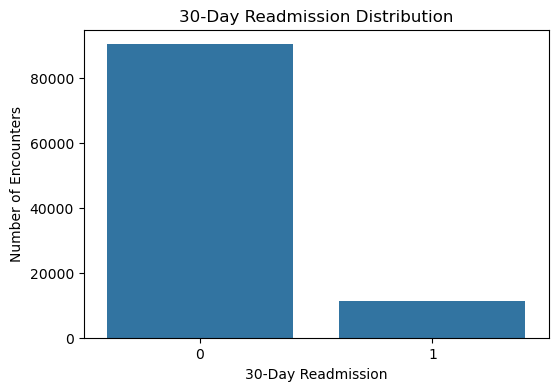

In [13]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="readmitted_30")

plt.title("30-Day Readmission Distribution")
plt.xlabel("30-Day Readmission")
plt.ylabel("Number of Encounters")

plt.show()

## Patient character 
### Age


In [15]:
df["age"].value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

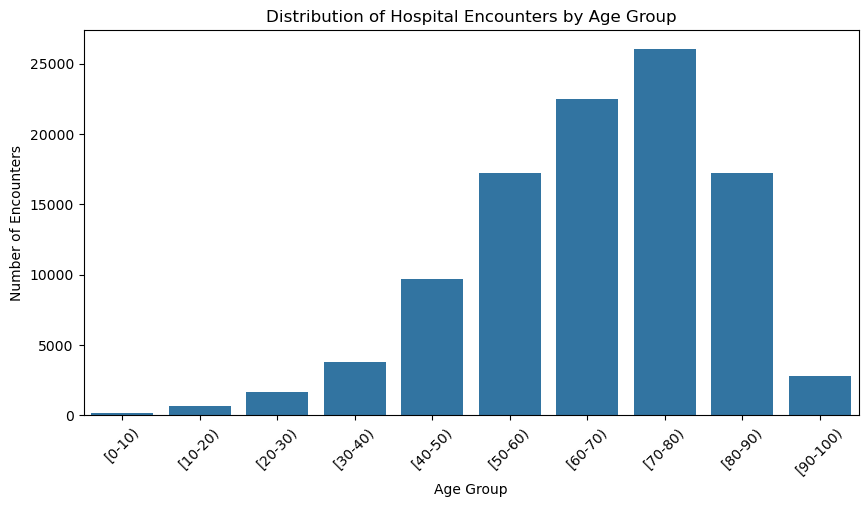

In [17]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="age", order=sorted(df["age"].dropna().unique()))

plt.title("Distribution of Hospital Encounters by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)

plt.show()

In [19]:
age_readmission = (
    df.groupby("age")["readmitted_30"]
      .mean()
      .mul(100)
      .reset_index(name="readmission_rate")
)

age_readmission

,age,readmission_rate
0,[0-10),1.863354
1,[10-20),5.788712
2,[20-30),14.242607
3,[30-40),11.231788
4,[40-50),10.604027
5,[50-60),9.666203
6,[60-70),11.128408
7,[70-80),11.773055
8,[80-90),12.083503
9,[90-100),11.099177


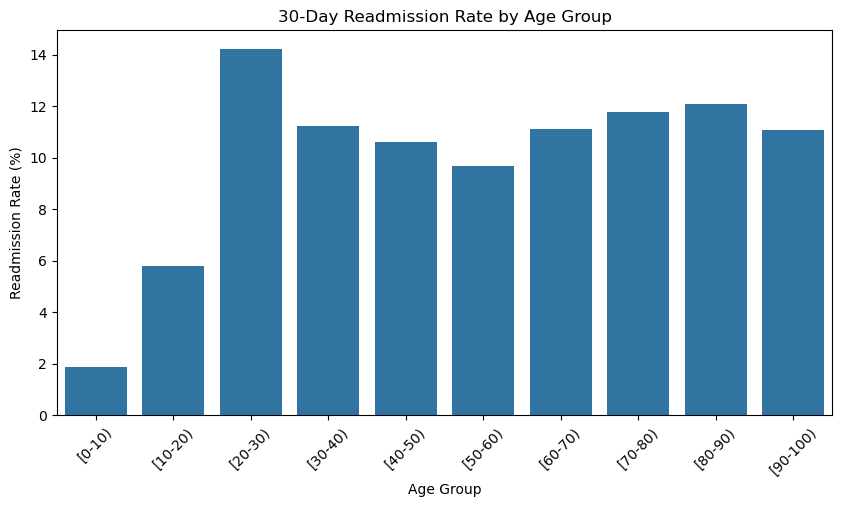

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_readmission,
    x="age",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [23]:
age_summary = (
    df.groupby("age")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

age_summary["readmission_rate"] = age_summary["mean"] * 100

age_summary

,age,count,sum,mean,readmission_rate
0,[0-10),161,3,0.018634,1.863354
1,[10-20),691,40,0.057887,5.788712
2,[20-30),1657,236,0.142426,14.242607
3,[30-40),3775,424,0.112318,11.231788
4,[40-50),9685,1027,0.106040,10.604027
5,[50-60),17256,1668,0.096662,9.666203
6,[60-70),22483,2502,0.111284,11.128408
7,[70-80),26068,3069,0.117731,11.773055
8,[80-90),17197,2078,0.120835,12.083503
9,[90-100),2793,310,0.110992,11.099177


### Gender

In [25]:
df["gender"].value_counts()

gender
Female    54708
Male      47055
Name: count, dtype: int64

In [27]:
gender_readmission = (
    df.groupby("gender")["readmitted_30"]
      .mean()
      .mul(100)
      .reset_index(name="readmission_rate")
)

gender_readmission

,gender,readmission_rate
0,Female,11.245156
1,Male,11.061524


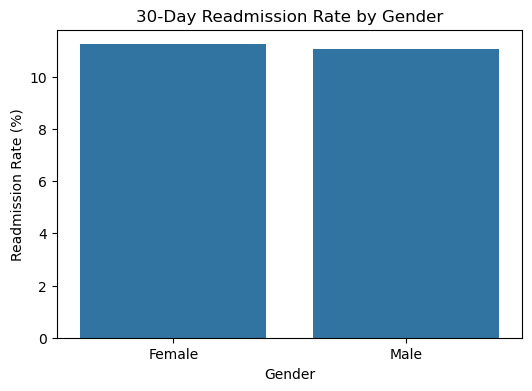

In [30]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=gender_readmission,
    x="gender",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Readmission Rate (%)")

plt.show()

### Race

In [32]:
df["race"].value_counts(dropna=False)

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

In [34]:
race_readmission = (
    df.groupby("race", dropna=False)["readmitted_30"]
      .mean()
      .mul(100)
      .reset_index(name="readmission_rate")
)

race_readmission

,race,readmission_rate
0,AfricanAmerican,11.218116
1,Asian,10.140406
2,Caucasian,11.290556
3,Hispanic,10.407462
4,Other,9.628154
5,NaN,8.271007


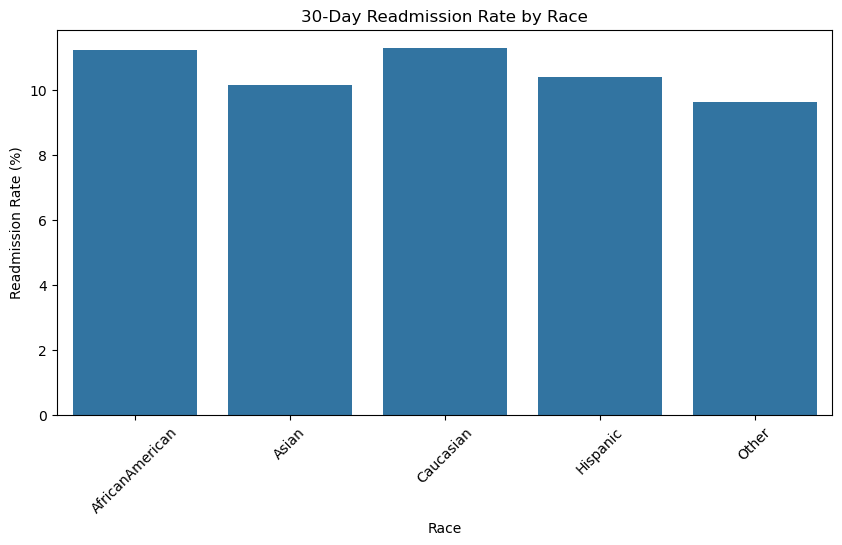

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=race_readmission,
    x="race",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Race")
plt.xlabel("Race")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)

plt.show()

### number_inpatient

In [38]:
df["number_inpatient"].describe()

count    101766.000000
mean          0.635566
std           1.262863
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          21.000000
Name: number_inpatient, dtype: float64

In [41]:
df["number_inpatient"].value_counts().sort_index()

number_inpatient
0     67630
1     19521
2      7566
3      3411
4      1622
5       812
6       480
7       268
8       151
9       111
10       61
11       49
12       34
13       20
14       10
15        9
16        6
17        1
18        1
19        2
21        1
Name: count, dtype: int64

In [42]:
inpatient_readmission = (
    df.groupby("number_inpatient")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

inpatient_readmission["readmission_rate"] = (
    inpatient_readmission["mean"] * 100
)

inpatient_readmission

,number_inpatient,count,sum,mean,readmission_rate
0,0,67630,5706,0.084371,8.437084
1,1,19521,2523,0.129245,12.924543
2,2,7566,1319,0.174333,17.433254
3,3,3411,692,0.202873,20.287306
4,4,1622,383,0.236128,23.612824
5,5,812,255,0.314039,31.403941
6,6,480,166,0.345833,34.583333
7,7,268,95,0.354478,35.447761
8,8,151,67,0.443709,44.370861
9,9,111,47,0.423423,42.342342


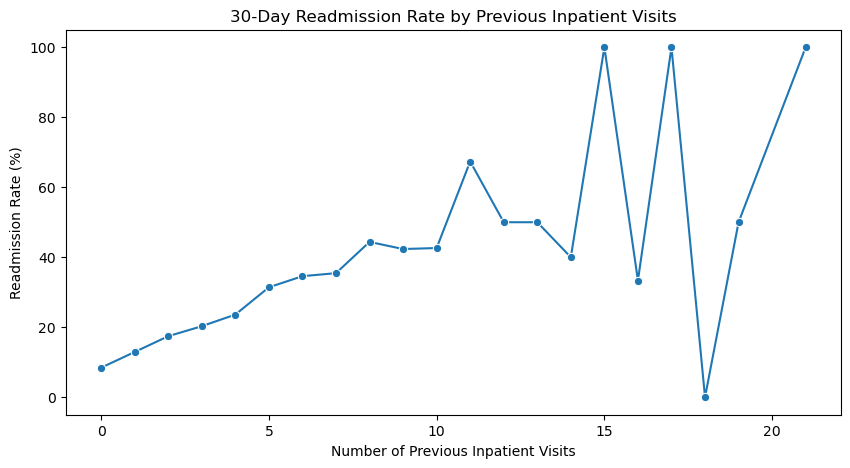

In [45]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=inpatient_readmission,
    x="number_inpatient",
    y="readmission_rate",
    marker="o"
)

plt.title("30-Day Readmission Rate by Previous Inpatient Visits")
plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [47]:
inpatient_readmission[
    inpatient_readmission["number_inpatient"] >= 5
]

,number_inpatient,count,sum,mean,readmission_rate
5,5,812,255,0.314039,31.403941
6,6,480,166,0.345833,34.583333
7,7,268,95,0.354478,35.447761
8,8,151,67,0.443709,44.370861
9,9,111,47,0.423423,42.342342
10,10,61,26,0.426230,42.622951
11,11,49,33,0.673469,67.346939
12,12,34,17,0.500000,50.000000
13,13,20,10,0.500000,50.000000
14,14,10,4,0.400000,40.000000


In [49]:
df["inpatient_visit_group"] = pd.cut(
    df["number_inpatient"],
    bins=[-1, 0, 1, 2, 4, float("inf")],
    labels=["0", "1", "2", "3-4", "5+"]
)


In [51]:
inpatient_group_readmission = (
    df.groupby("inpatient_visit_group", observed=True)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

inpatient_group_readmission["readmission_rate"] = (
    inpatient_group_readmission["mean"] * 100
)

inpatient_group_readmission

,inpatient_visit_group,count,sum,mean,readmission_rate
0,0,67630,5706,0.084371,8.437084
1,1,19521,2523,0.129245,12.924543
2,2,7566,1319,0.174333,17.433254
3,3-4,5033,1075,0.213590,21.359030
4,5+,2016,734,0.364087,36.408730


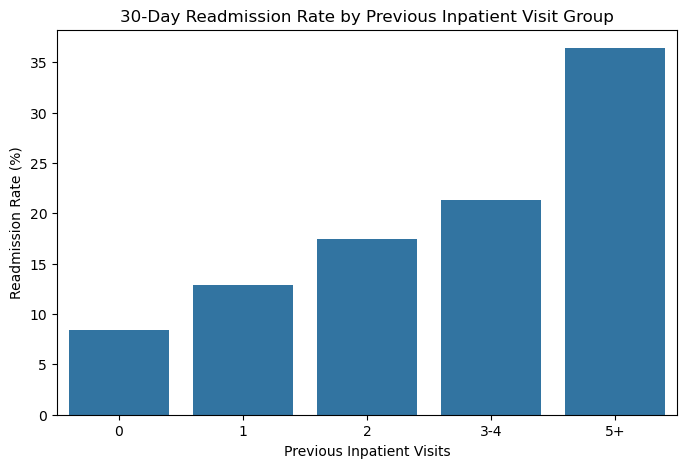

In [53]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=inpatient_group_readmission,
    x="inpatient_visit_group",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Previous Inpatient Visit Group")
plt.xlabel("Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")

plt.show()

## Emergency and Outpatient utilization
### Emergency visits

In [54]:
df["number_emergency"].describe()


count    101766.000000
mean          0.197836
std           0.930472
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          76.000000
Name: number_emergency, dtype: float64

In [56]:
df["number_emergency"].value_counts().sort_index()

number_emergency
0     90383
1      7677
2      2042
3       725
4       374
5       192
6        94
7        73
8        50
9        33
10       34
11       23
12       10
13       12
14        3
15        3
16        5
18        5
19        4
20        4
21        2
22        6
24        1
25        2
28        1
29        1
37        1
42        1
46        1
54        1
63        1
64        1
76        1
Name: count, dtype: int64

In [58]:
emergency_readmission = (
    df.groupby("number_emergency")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

emergency_readmission["readmission_rate"] = (
    emergency_readmission["mean"] * 100
)

emergency_readmission

,number_emergency,count,sum,mean,readmission_rate
0,0,90383,9467,0.104743,10.474315
1,1,7677,1102,0.143546,14.354566
2,2,2042,373,0.182664,18.266405
3,3,725,147,0.202759,20.275862
4,4,374,115,0.307487,30.748663
5,5,192,47,0.244792,24.479167
6,6,94,22,0.234043,23.404255
7,7,73,19,0.260274,26.027397
8,8,50,16,0.320000,32.000000
9,9,33,12,0.363636,36.363636


In [62]:
df["emergency_visit_group"] = pd.cut(
    df["number_emergency"],
    bins=[-1, 0, 1, 2, 4, float("inf")],
    labels=["0", "1", "2", "3-4", "5+"]
)

In [63]:
emergency_group_readmission = (
    df.groupby("emergency_visit_group", observed=True)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

emergency_group_readmission["readmission_rate"] = (
    emergency_group_readmission["mean"] * 100
)

emergency_group_readmission

,emergency_visit_group,count,sum,mean,readmission_rate
0,0,90383,9467,0.104743,10.474315
1,1,7677,1102,0.143546,14.354566
2,2,2042,373,0.182664,18.266405
3,3-4,1099,262,0.238399,23.839854
4,5+,565,153,0.270796,27.079646


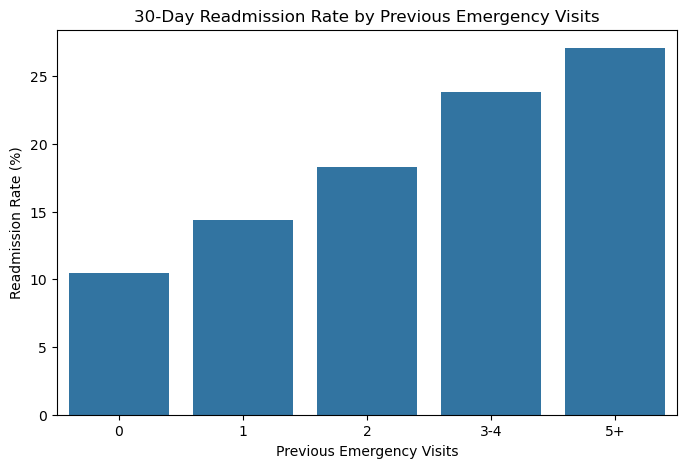

In [65]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=emergency_group_readmission,
    x="emergency_visit_group",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Previous Emergency Visits")
plt.xlabel("Previous Emergency Visits")
plt.ylabel("Readmission Rate (%)")

plt.show()

### Outpatient visits

In [67]:
df["number_outpatient"].describe()

count    101766.000000
mean          0.369357
std           1.267265
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          42.000000
Name: number_outpatient, dtype: float64

In [68]:
df["number_outpatient"].value_counts().sort_index()

number_outpatient
0     85027
1      8547
2      3594
3      2042
4      1099
5       533
6       303
7       155
8        98
9        83
10       57
11       42
12       30
13       31
14       28
15       20
16       15
17        8
18        5
19        3
20        7
21        7
22        5
23        2
24        3
25        2
26        2
27        3
28        1
29        2
33        2
34        1
35        2
36        2
37        1
38        1
39        1
40        1
42        1
Name: count, dtype: int64

In [70]:
outpatient_readmission = (
    df.groupby("number_outpatient")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

outpatient_readmission["readmission_rate"] = (
    outpatient_readmission["mean"] * 100
)

outpatient_readmission

,number_outpatient,count,sum,mean,readmission_rate
0,0,85027,9076,0.106743,10.674256
1,1,8547,1190,0.139230,13.923014
2,2,3594,494,0.137451,13.745131
3,3,2042,251,0.122919,12.291871
4,4,1099,166,0.151046,15.104641
5,5,533,63,0.118199,11.819887
6,6,303,40,0.132013,13.201320
7,7,155,24,0.154839,15.483871
8,8,98,5,0.051020,5.102041
9,9,83,13,0.156627,15.662651


In [72]:
df["outpatient_visit_group"] = pd.cut(
    df["number_outpatient"],
    bins=[-1, 0, 1, 2, 4, 8, float("inf")],
    labels=["0", "1", "2", "3-4", "5-8", "9+"]
)

In [74]:
outpatient_group_readmission = (
    df.groupby("outpatient_visit_group", observed=True)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

outpatient_group_readmission["readmission_rate"] = (
    outpatient_group_readmission["mean"] * 100
)

outpatient_group_readmission


,outpatient_visit_group,count,sum,mean,readmission_rate
0,0,85027,9076,0.106743,10.674256
1,1,8547,1190,0.139230,13.923014
2,2,3594,494,0.137451,13.745131
3,3-4,3141,417,0.132760,13.276027
4,5-8,1089,132,0.121212,12.121212
5,9+,368,48,0.130435,13.043478


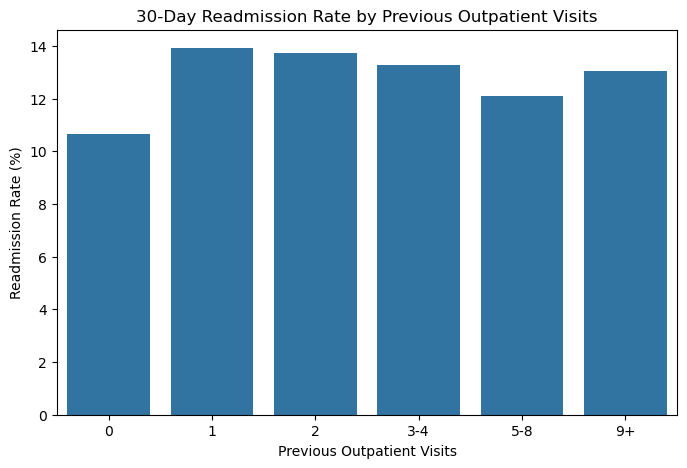

In [76]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=outpatient_group_readmission,
    x="outpatient_visit_group",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Previous Outpatient Visits")
plt.xlabel("Previous Outpatient Visits")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [78]:
outpatient_group_readmission[["outpatient_visit_group", "count", "sum", "readmission_rate"]]

,outpatient_visit_group,count,sum,readmission_rate
0,0,85027,9076,10.674256
1,1,8547,1190,13.923014
2,2,3594,494,13.745131
3,3-4,3141,417,13.276027
4,5-8,1089,132,12.121212
5,9+,368,48,13.043478


In [80]:
emergency_group_readmission[
    ["emergency_visit_group", "count", "sum", "readmission_rate"]
]


,emergency_visit_group,count,sum,readmission_rate
0,0,90383,9467,10.474315
1,1,7677,1102,14.354566
2,2,2042,373,18.266405
3,3-4,1099,262,23.839854
4,5+,565,153,27.079646


In [82]:
df[
    [
        "time_in_hospital",
        "num_lab_procedures",
        "num_procedures",
        "num_medications",
        "number_diagnoses"
    ]
].describe()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.933600
min,1.000000,1.000000,0.000000,1.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,16.000000


In [84]:
los_readmission = (
    df.groupby("time_in_hospital")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

los_readmission["readmission_rate"] = los_readmission["mean"] * 100

los_readmission

,time_in_hospital,count,sum,mean,readmission_rate
0,1,14208,1162,0.081785,8.178491
1,2,17224,1712,0.099396,9.939619
2,3,17756,1894,0.106668,10.666817
3,4,13924,1644,0.118070,11.806952
4,5,9966,1199,0.120309,12.030905
5,6,7539,949,0.125879,12.587876
6,7,5859,752,0.128350,12.834955
7,8,4391,625,0.142337,14.233660
8,9,3002,412,0.137242,13.724184
9,10,2342,336,0.143467,14.346712


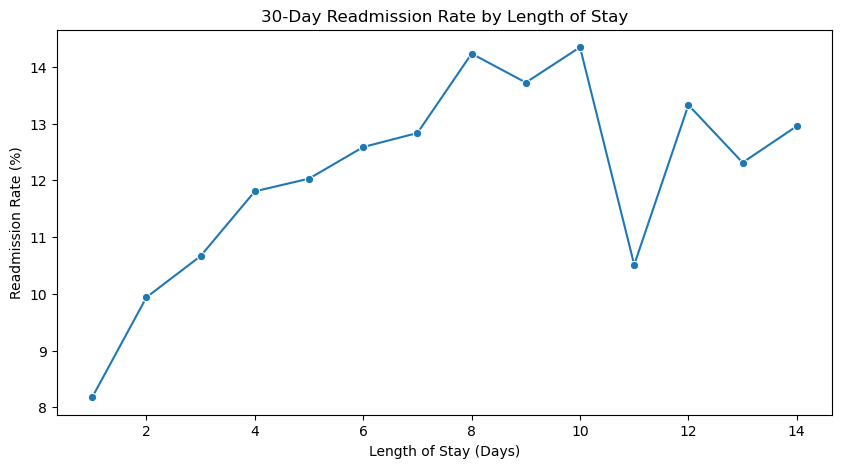

In [86]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=los_readmission,
    x="time_in_hospital",
    y="readmission_rate",
    marker="o"
)

plt.title("30-Day Readmission Rate by Length of Stay")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Readmission Rate (%)")

plt.show()

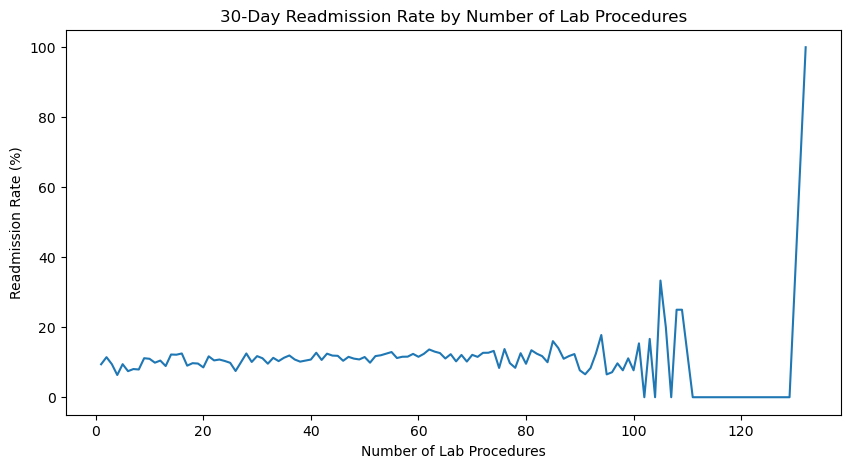

In [88]:
lab_readmission = (
    df.groupby("num_lab_procedures")["readmitted_30"]
      .mean()
      .mul(100)
      .reset_index(name="readmission_rate")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=lab_readmission,
    x="num_lab_procedures",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Number of Lab Procedures")
plt.xlabel("Number of Lab Procedures")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [90]:
procedure_readmission = (
    df.groupby("num_procedures")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

procedure_readmission["readmission_rate"] = (
    procedure_readmission["mean"] * 100
)

procedure_readmission

,num_procedures,count,sum,mean,readmission_rate
0,0,46652,5168,0.110778,11.077767
1,1,20742,2532,0.122071,12.207116
2,2,12717,1422,0.111819,11.181883
3,3,9443,1009,0.106852,10.685164
4,4,4180,461,0.110287,11.028708
5,5,3078,290,0.094217,9.421702
6,6,4954,475,0.095882,9.588212


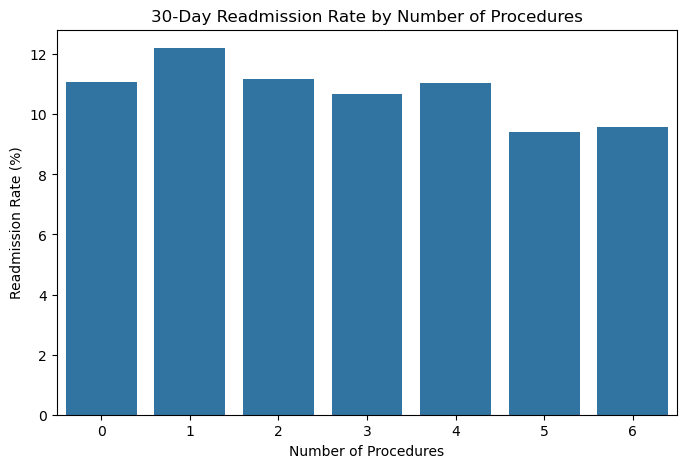

In [92]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=procedure_readmission,
    x="num_procedures",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Number of Procedures")
plt.xlabel("Number of Procedures")
plt.ylabel("Readmission Rate (%)")

plt.show()

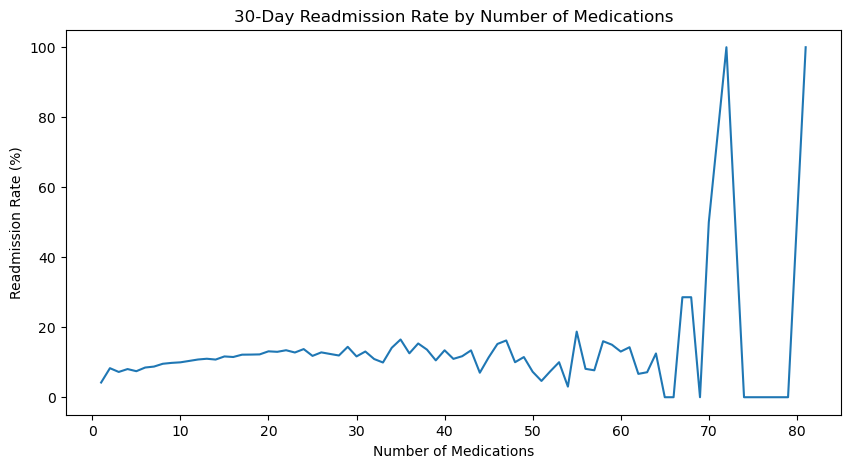

In [94]:
medication_readmission = (
    df.groupby("num_medications")["readmitted_30"]
      .mean()
      .mul(100)
      .reset_index(name="readmission_rate")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=medication_readmission,
    x="num_medications",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Number of Medications")
plt.xlabel("Number of Medications")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [96]:
diagnosis_readmission = (
    df.groupby("number_diagnoses")["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

diagnosis_readmission["readmission_rate"] = (
    diagnosis_readmission["mean"] * 100
)

diagnosis_readmission

,number_diagnoses,count,sum,mean,readmission_rate
0,1,219,13,0.059361,5.936073
1,2,1023,62,0.060606,6.060606
2,3,2835,209,0.073721,7.372134
3,4,5537,457,0.082536,8.253567
4,5,11393,1043,0.091547,9.154744
5,6,10161,1058,0.104124,10.412361
6,7,10393,1119,0.107669,10.766862
7,8,10616,1254,0.118124,11.812359
8,9,49474,6125,0.123802,12.380240
9,10,17,3,0.176471,17.647059


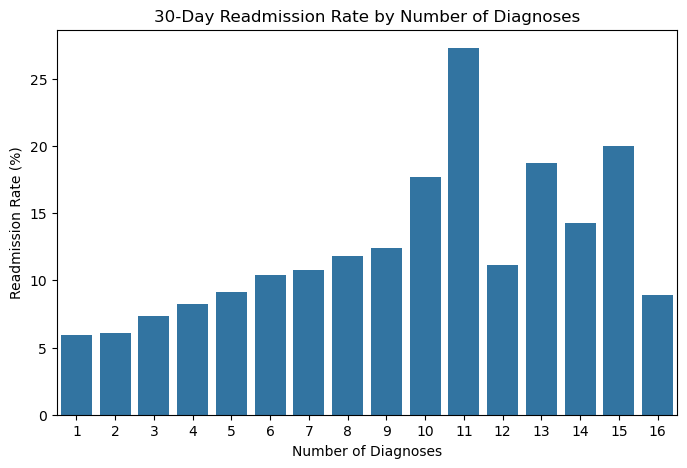

In [98]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=diagnosis_readmission,
    x="number_diagnoses",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Number of Diagnoses")
plt.xlabel("Number of Diagnoses")
plt.ylabel("Readmission Rate (%)")

plt.show()

### Admission type

In [99]:
df["admission_type"].value_counts(dropna=False)


admission_type
Emergency        53990
Elective         18869
Urgent           18480
NaN               5291
Not Available     4785
Not Mapped         320
Trauma Center       21
Newborn             10
Name: count, dtype: int64

In [101]:
admission_type_readmission = (
    df.groupby("admission_type", dropna=False)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

admission_type_readmission["readmission_rate"] = (
    admission_type_readmission["mean"] * 100
)

admission_type_readmission

,admission_type,count,sum,mean,readmission_rate
0,Elective,18869,1961,0.103927,10.392708
1,Emergency,53990,6221,0.115225,11.522504
2,Newborn,10,1,0.100000,10.000000
3,Not Available,4785,495,0.103448,10.344828
4,Not Mapped,320,27,0.084375,8.437500
5,Trauma Center,21,0,0.000000,0.000000
6,Urgent,18480,2066,0.111797,11.179654
7,NaN,5291,586,0.110754,11.075411


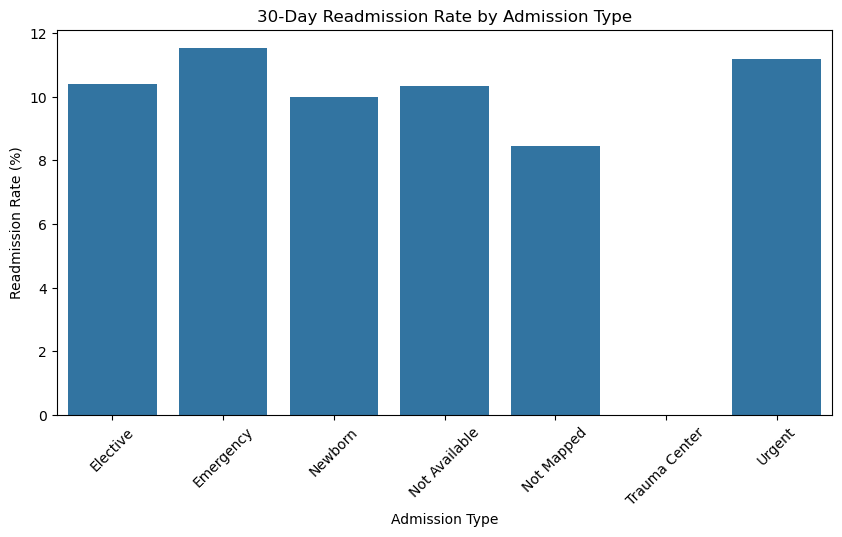

In [103]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=admission_type_readmission,
    x="admission_type",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)

plt.show()

### Admission source

In [105]:
df["admission_source"].value_counts(dropna=False)

admission_source
 Emergency Room                                               57494
 Physician Referral                                           29565
NaN                                                            6781
Transfer from a hospital                                       3187
 Transfer from another health care facility                    2264
Clinic Referral                                                1104
 Transfer from a Skilled Nursing Facility (SNF)                 855
HMO Referral                                                    187
 Not Mapped                                                     161
 Not Available                                                  125
 Court/Law Enforcement                                           16
 Transfer from hospital inpt/same fac reslt in a sep claim       12
 Transfer from critial access hospital                            8
 Extramural Birth                                                 2
Normal Delivery                

In [107]:
admission_source_readmission = (
    df.groupby("admission_source", dropna=False)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

admission_source_readmission["readmission_rate"] = (
    admission_source_readmission["mean"] * 100
)

admission_source_readmission.sort_values(
    "readmission_rate",
    ascending=False
)

,admission_source,count,sum,mean,readmission_rate
11,Transfer from hospital inpt/same fac reslt in...,12,2,0.166667,16.666667
13,HMO Referral,187,29,0.155080,15.508021
4,Not Mapped,161,22,0.136646,13.664596
0,Court/Law Enforcement,16,2,0.125000,12.500000
8,Transfer from a Skilled Nursing Facility (SNF),855,101,0.118129,11.812865
1,Emergency Room,57494,6720,0.116882,11.688176
5,Physician Referral,29565,3130,0.105868,10.586843
16,NaN,6781,706,0.104114,10.411444
3,Not Available,125,13,0.104000,10.400000
12,Clinic Referral,1104,111,0.100543,10.054348


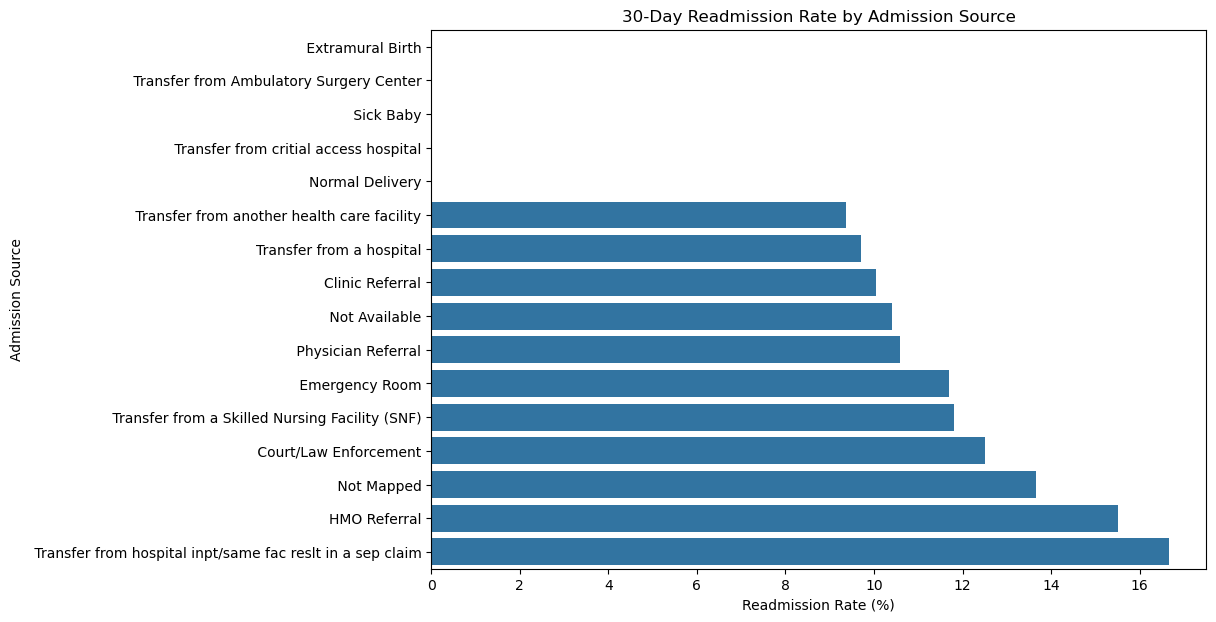

In [109]:
source_plot = admission_source_readmission.sort_values(
    "readmission_rate",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=source_plot,
    x="readmission_rate",
    y="admission_source"
)

plt.title("30-Day Readmission Rate by Admission Source")
plt.xlabel("Readmission Rate (%)")
plt.ylabel("Admission Source")

plt.show()

### Discharge disposition

In [111]:
df["discharge_disposition"].value_counts(dropna=False)

discharge_disposition
Discharged to home                                                                                           60234
Discharged/transferred to SNF                                                                                13954
Discharged/transferred to home with home health service                                                      12902
NaN                                                                                                           3691
Discharged/transferred to another short term hospital                                                         2128
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1993
Expired                                                                                                       1642
Discharged/transferred to another type of inpatient care institution                                          1184
Not Mapped                                                

In [113]:
disposition_readmission = (
    df.groupby("discharge_disposition", dropna=False)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

disposition_readmission["readmission_rate"] = (
    disposition_readmission["mean"] * 100
)

disposition_readmission.sort_values(
    "readmission_rate",
    ascending=False
)

,discharge_disposition,count,sum,mean,readmission_rate
24,Still patient or expected to return for outpat...,3,2,0.666667,66.666667
12,Discharged/transferred within this institution...,63,28,0.444444,44.444444
0,Admitted as an inpatient to this hospital,21,9,0.428571,42.857143
14,Discharged/transferred/referred to a psychiatr...,139,51,0.366906,36.690647
7,Discharged/transferred to another rehab fac in...,1993,552,0.276969,27.696939
9,Discharged/transferred to another type of inpa...,1184,247,0.208615,20.861486
8,Discharged/transferred to another short term h...,2128,342,0.160714,16.071429
3,Discharged/transferred to SNF,13954,2046,0.146625,14.662462
6,Discharged/transferred to a nursing facility c...,48,7,0.145833,14.583333
21,Left AMA,623,90,0.144462,14.446228


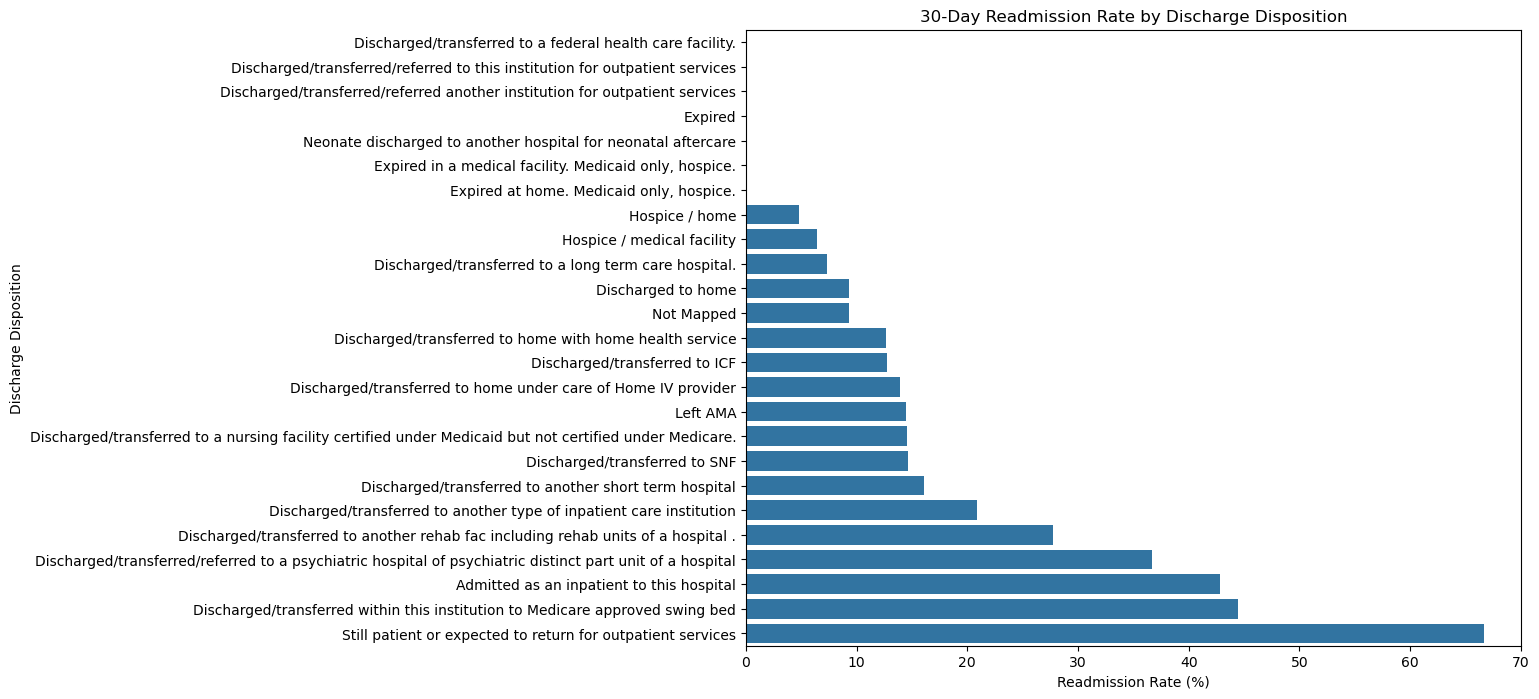

In [115]:
disposition_plot = disposition_readmission.sort_values(
    "readmission_rate",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=disposition_plot,
    x="readmission_rate",
    y="discharge_disposition"
)

plt.title("30-Day Readmission Rate by Discharge Disposition")
plt.xlabel("Readmission Rate (%)")
plt.ylabel("Discharge Disposition")

plt.show()

## Clinical factors

In [117]:
df["A1Cresult"].value_counts(dropna=False)

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

In [119]:
a1c_readmission = (
    df.groupby("A1Cresult", dropna=False)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

a1c_readmission["readmission_rate"] = (
    a1c_readmission["mean"] * 100
)

a1c_readmission

,A1Cresult,count,sum,mean,readmission_rate
0,>7,3812,383,0.100472,10.047219
1,>8,8216,811,0.098710,9.870983
2,Norm,4990,482,0.096593,9.659319
3,NaN,84748,9681,0.114233,11.423278


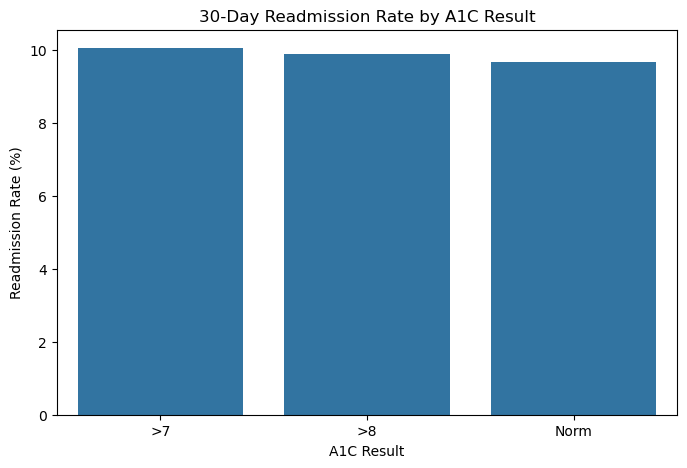

In [121]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=a1c_readmission,
    x="A1Cresult",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by A1C Result")
plt.xlabel("A1C Result")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [123]:
df["diabetesMed"].value_counts(dropna=False)

diabetesMed
Yes    78363
No     23403
Name: count, dtype: int64

In [125]:
diabetes_med_readmission = (
    df.groupby("diabetesMed", dropna=False)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

diabetes_med_readmission["readmission_rate"] = (
    diabetes_med_readmission["mean"] * 100
)

diabetes_med_readmission

,diabetesMed,count,sum,mean,readmission_rate
0,No,23403,2246,0.095971,9.597060
1,Yes,78363,9111,0.116267,11.626661


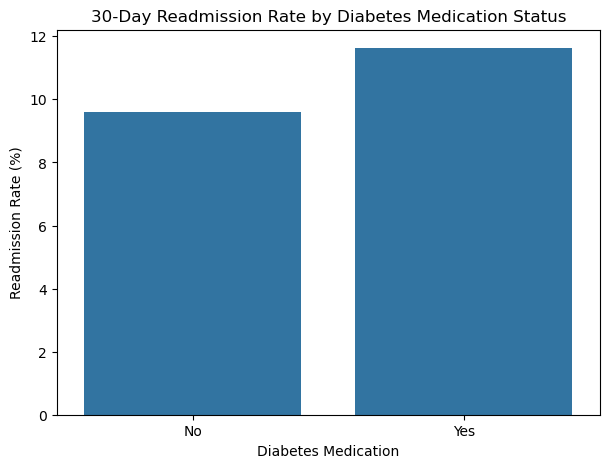

In [127]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=diabetes_med_readmission,
    x="diabetesMed",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Diabetes Medication Status")
plt.xlabel("Diabetes Medication")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [129]:
df["change"].value_counts(dropna=False)

change
No    54755
Ch    47011
Name: count, dtype: int64

In [131]:
change_readmission = (
    df.groupby("change", dropna=False)["readmitted_30"]
      .agg(["count", "sum", "mean"])
      .reset_index()
)

change_readmission["readmission_rate"] = (
    change_readmission["mean"] * 100
)

change_readmission

,change,count,sum,mean,readmission_rate
0,Ch,47011,5558,0.118228,11.822765
1,No,54755,5799,0.105908,10.590814


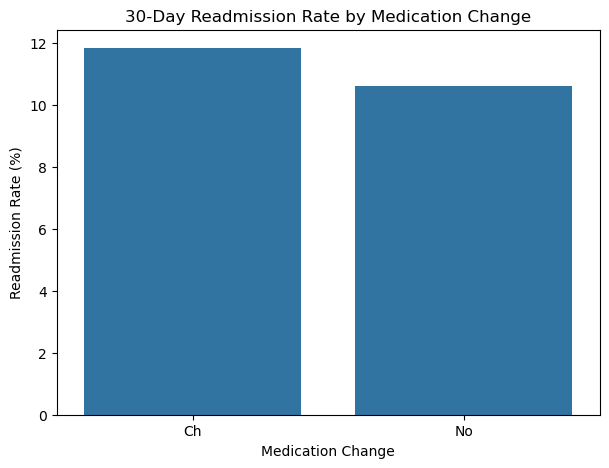

In [133]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=change_readmission,
    x="change",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by Medication Change")
plt.xlabel("Medication Change")
plt.ylabel("Readmission Rate (%)")

plt.show()

## A1C + medication-related variables

In [135]:
a1c_readmission

,A1Cresult,count,sum,mean,readmission_rate
0,>7,3812,383,0.100472,10.047219
1,>8,8216,811,0.098710,9.870983
2,Norm,4990,482,0.096593,9.659319
3,NaN,84748,9681,0.114233,11.423278


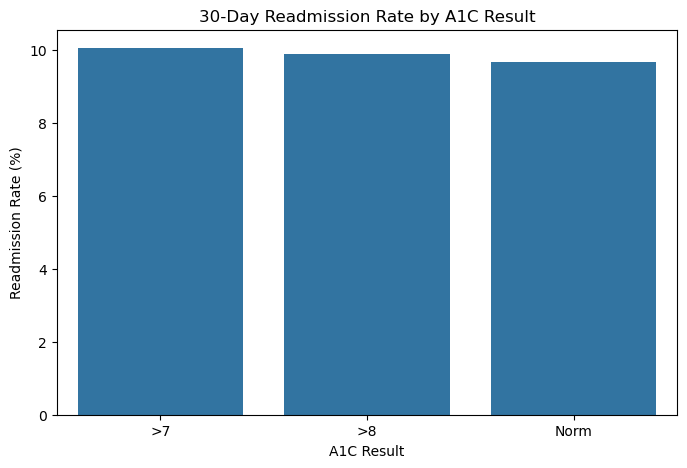

In [137]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=a1c_readmission,
    x="A1Cresult",
    y="readmission_rate"
)

plt.title("30-Day Readmission Rate by A1C Result")
plt.xlabel("A1C Result")
plt.ylabel("Readmission Rate (%)")

plt.show()

In [139]:
medication_columns = [
    col for col in df.columns
    if col in [
        "metformin", "repaglinide", "nateglinide",
        "chlorpropamide", "glimepiride", "acetohexamide",
        "glipizide", "glyburide", "tolbutamide",
        "pioglitazone", "rosiglitazone", "acarbose",
        "miglitol", "troglitazone", "tolazamide",
        "insulin", "glyburide-metformin",
        "glipizide-metformin", "glimepiride-pioglitazone",
        "metformin-rosiglitazone", "metformin-pioglitazone"
    ]
]

medication_columns

['metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone']

In [141]:
medication_results = []

for col in medication_columns:
    result = (
        df.groupby(col)["readmitted_30"]
          .agg(["count", "sum", "mean"])
          .reset_index()
    )
    
    result["readmission_rate"] = result["mean"] * 100
    result["medication"] = col
    
    medication_results.append(result)

medication_readmission = pd.concat(
    medication_results,
    ignore_index=True
)

medication_readmission[
    ["medication", medication_columns[0], "count", "sum", "readmission_rate"]
].head()

,medication,metformin,count,sum,readmission_rate
0,metformin,Down,575,69,12.000000
1,metformin,No,81778,9418,11.516545
2,metformin,Steady,18346,1782,9.713289
3,metformin,Up,1067,88,8.247423
4,repaglinide,NaN,45,3,6.666667


In [143]:
medication_summary = []

for col in medication_columns:
    for status in ["No", "Yes"]:
        subset = df[df[col] == status]
        
        medication_summary.append({
            "medication": col,
            "status": status,
            "count": len(subset),
            "readmissions": subset["readmitted_30"].sum(),
            "readmission_rate": subset["readmitted_30"].mean() * 100
        })

medication_summary = pd.DataFrame(medication_summary)

medication_summary

,medication,status,count,readmissions,readmission_rate
0,metformin,No,81778,9418,11.516545
1,metformin,Yes,0,0,NaN
2,repaglinide,No,100227,11152,11.126742
3,repaglinide,Yes,0,0,NaN
4,nateglinide,No,101063,11277,11.158386
5,nateglinide,Yes,0,0,NaN
6,chlorpropamide,No,101680,11352,11.164437
7,chlorpropamide,Yes,0,0,NaN
8,glimepiride,No,96575,10827,11.210976
9,glimepiride,Yes,0,0,NaN


In [145]:
medication_comparison = (
    medication_summary
    .pivot(
        index="medication",
        columns="status",
        values="readmission_rate"
    )
    .reset_index()
)

medication_comparison["difference"] = (
    medication_comparison["Yes"] -
    medication_comparison["No"]
)

medication_comparison.sort_values(
    "difference",
    ascending=False
)

status,medication,No,Yes,difference
0,acarbose,11.166197,NaN,NaN
1,acetohexamide,11.160026,NaN,NaN
2,chlorpropamide,11.164437,NaN,NaN
3,glimepiride,11.210976,NaN,NaN
4,glimepiride-pioglitazone,11.160026,NaN,NaN
5,glipizide,11.119219,NaN,NaN
6,glipizide-metformin,11.160359,NaN,NaN
7,glyburide,11.221959,NaN,NaN
8,glyburide-metformin,11.160697,NaN,NaN
9,insulin,10.037355,NaN,NaN


In [147]:
medication_summary.sort_values(
    ["medication", "status"]
)

,medication,status,count,readmissions,readmission_rate
22,acarbose,No,101458,11329,11.166197
23,acarbose,Yes,0,0,NaN
10,acetohexamide,No,101765,11357,11.160026
11,acetohexamide,Yes,0,0,NaN
6,chlorpropamide,No,101680,11352,11.164437
7,chlorpropamide,Yes,0,0,NaN
8,glimepiride,No,96575,10827,11.210976
9,glimepiride,Yes,0,0,NaN
36,glimepiride-pioglitazone,No,101765,11357,11.160026
37,glimepiride-pioglitazone,Yes,0,0,NaN


In [149]:
medication_comparison.sort_values("difference", ascending=False)

status,medication,No,Yes,difference
0,acarbose,11.166197,NaN,NaN
1,acetohexamide,11.160026,NaN,NaN
2,chlorpropamide,11.164437,NaN,NaN
3,glimepiride,11.210976,NaN,NaN
4,glimepiride-pioglitazone,11.160026,NaN,NaN
5,glipizide,11.119219,NaN,NaN
6,glipizide-metformin,11.160359,NaN,NaN
7,glyburide,11.221959,NaN,NaN
8,glyburide-metformin,11.160697,NaN,NaN
9,insulin,10.037355,NaN,NaN


### Diagnosis / clinical complexity

In [151]:
df["diag_1"].value_counts().head(20)

diag_1
428      6862
414      6581
786      4016
410      3614
486      3508
427      2766
491      2275
715      2151
682      2042
434      2028
780      2019
996      1967
276      1889
38       1688
250.8    1680
599      1595
584      1520
V57      1207
250.6    1183
518      1115
Name: count, dtype: int64

In [153]:
df["diag_2"].value_counts().head(20)

diag_2
276       6752
428       6662
250       6071
427       5036
401       3736
496       3305
599       3288
403       2823
414       2650
411       2566
250.02    2074
707       1999
585       1871
584       1649
491       1545
250.01    1523
285       1520
780       1491
425       1434
682       1433
Name: count, dtype: int64

In [155]:
df["diag_3"].value_counts().head(20)

diag_3
250       11555
401        8289
276        5175
428        4577
427        3955
414        3664
496        2605
403        2357
585        1992
272        1969
599        1941
V45        1389
250.02     1369
707        1360
780        1334
285        1200
425        1136
250.6      1080
424        1063
584         963
Name: count, dtype: int64

In [157]:
missing_summary = (
    df.isna()
      .sum()
      .reset_index()
)

missing_summary.columns = ["column", "missing_count"]

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"] / len(df) * 100
)

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

missing_summary.head(15)

,column,missing_count,missing_percentage
21,A1Cresult,84748,83.277322
10,medical_specialty,49949,49.082208
9,payer_code,40256,39.557416
48,admission_source,6781,6.663326
46,admission_type,5291,5.199182
47,discharge_disposition,3691,3.626948
2,race,2273,2.233555
19,diag_3,1423,1.398306
18,diag_2,358,0.351787
17,diag_1,21,0.020636


In [159]:
missing_columns = (
    missing_summary[missing_summary["missing_count"] > 0]["column"]
    .tolist()
)

missing_readmission = []

for col in missing_columns:
    missing_flag = df[col].isna()
    
    result = df.groupby(missing_flag)["readmitted_30"].mean() * 100
    
    for is_missing, rate in result.items():
        missing_readmission.append({
            "column": col,
            "missing": is_missing,
            "readmission_rate": rate,
            "count": missing_flag.sum() if is_missing else (~missing_flag).sum()
        })

missing_readmission = pd.DataFrame(missing_readmission)

missing_readmission.head(20)

,column,missing,readmission_rate,count
0,A1Cresult,False,9.848396,17018
1,A1Cresult,True,11.423278,84748
2,medical_specialty,False,10.760947,51817
3,medical_specialty,True,11.573805,49949
4,payer_code,False,10.941310,61510
5,payer_code,True,11.493939,40256
6,admission_source,False,11.213349,94985
7,admission_source,True,10.411444,6781
8,admission_type,False,11.164550,96475
9,admission_type,True,11.075411,5291


In [161]:
missing_summary.head(15)

,column,missing_count,missing_percentage
21,A1Cresult,84748,83.277322
10,medical_specialty,49949,49.082208
9,payer_code,40256,39.557416
48,admission_source,6781,6.663326
46,admission_type,5291,5.199182
47,discharge_disposition,3691,3.626948
2,race,2273,2.233555
19,diag_3,1423,1.398306
18,diag_2,358,0.351787
17,diag_1,21,0.020636


In [163]:
missing_readmission.sort_values(
    ["column", "missing"]
)



,column,missing,readmission_rate,count
0,A1Cresult,False,9.848396,17018
1,A1Cresult,True,11.423278,84748
6,admission_source,False,11.213349,94985
7,admission_source,True,10.411444,6781
8,admission_type,False,11.164550,96475
9,admission_type,True,11.075411,5291
18,diag_1,False,11.157305,101745
19,diag_1,True,23.809524,21
16,diag_2,False,11.170716,101408
17,diag_2,True,8.100559,358


In [165]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

numeric_readmission_corr = (
    df[numeric_cols + ["readmitted_30"]]
    .corr()["readmitted_30"]
    .drop("readmitted_30")
    .sort_values(ascending=False)
)

numeric_readmission_corr

number_inpatient      0.165147
number_emergency      0.060747
number_diagnoses      0.049524
time_in_hospital      0.044199
num_medications       0.038432
num_lab_procedures    0.020364
number_outpatient     0.018893
num_procedures       -0.012227
Name: readmitted_30, dtype: float64

In [167]:
utilization_cols = [
    "number_inpatient",
    "number_emergency",
    "number_outpatient"
]

df[utilization_cols].corr()


,number_inpatient,number_emergency,number_outpatient
number_inpatient,1.000000,0.266559,0.107338
number_emergency,0.266559,1.000000,0.091459
number_outpatient,0.107338,0.091459,1.000000


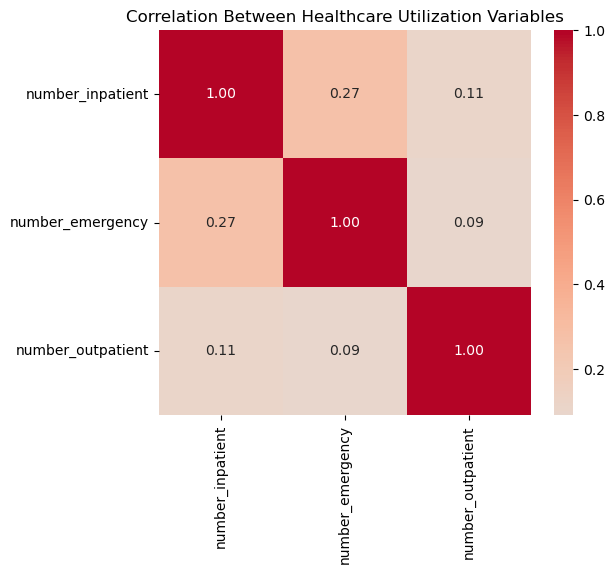

In [169]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    df[utilization_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Healthcare Utilization Variables")

plt.show()

In [171]:
eda_findings = pd.DataFrame({
    "Variable": [
        "Age",
        "Gender",
        "Race",
        "Previous inpatient visits",
        "Previous emergency visits",
        "Previous outpatient visits",
        "Number of diagnoses",
        "Diabetes medication",
        "Medication change",
        "A1C result",
        "Admission type",
        "Admission source",
        "Discharge disposition",
        "Raw diagnosis codes"
    ],
    
    "Observed_pattern": [
        "Readmission rates vary across age groups; relationship is not monotonic.",
        "Very similar readmission rates between genders.",
        "Some variation across race categories, but no strong standalone pattern.",
        "Strong increasing readmission rate as previous inpatient visits increase.",
        "Strong increasing readmission rate as previous emergency visits increase.",
        "Some difference, but no consistent increasing trend.",
        "Readmission rate generally increases with greater number of diagnoses, with some fluctuations.",
        "Patients on diabetes medication show a higher observed readmission rate.",
        "Small difference between medication-change groups.",
        "Little difference across observed A1C categories.",
        "Main admission types show relatively similar readmission rates.",
        "Some variation, but many categories have small sample sizes.",
        "Meaningful differences across some common discharge destinations.",
        "Individual ICD-9 codes are difficult to interpret directly; grouping is needed."
    ],
    
    "Feature_engineering_relevance": [
        "Consider retaining age group.",
        "Low priority based on univariate analysis.",
        "Consider only if clinically justified.",
        "High priority.",
        "High priority.",
        "Potential candidate.",
        "Potential candidate.",
        "Potential candidate.",
        "Lower priority.",
        "Retain for further consideration because of clinical relevance.",
        "Lower priority.",
        "Requires careful grouping.",
        "Potentially important; requires grouping of rare categories.",
        "Group into clinically meaningful diagnosis categories."
    ]
})

eda_findings

,Variable,Observed_pattern,Feature_engineering_relevance
0,Age,Readmission rates vary across age groups; rela...,Consider retaining age group.
1,Gender,Very similar readmission rates between genders.,Low priority based on univariate analysis.
2,Race,"Some variation across race categories, but no ...",Consider only if clinically justified.
3,Previous inpatient visits,Strong increasing readmission rate as previous...,High priority.
4,Previous emergency visits,Strong increasing readmission rate as previous...,High priority.
5,Previous outpatient visits,"Some difference, but no consistent increasing ...",Potential candidate.
6,Number of diagnoses,Readmission rate generally increases with grea...,Potential candidate.
7,Diabetes medication,Patients on diabetes medication show a higher ...,Potential candidate.
8,Medication change,Small difference between medication-change gro...,Lower priority.
9,A1C result,Little difference across observed A1C categories.,Retain for further consideration because of cl...
